# Delivery delay prediction and Slack alert system
## MapleFreight Logistics - Assessment 1 (AML 3303)

# Block 1 - Business context and environment setup

### Business context
MapleFreight Logistics handles around 8,000 weekly shipments across Canada. Recently, on-time deliveries dropped from 94% to 88%, leading to financial penalties and client dissatisfaction. The goal of this project is to analyze delivery data, build a machine learning classification model to identify high-risk shipments (**delivered_late**), and trigger automated alerts to Slack dispatchers before delays happen

### Student note and exploratory workflow
This notebook uses a step-by-step data science workflow. Every cleaning step, feature engineering decision, and modeling choice is preceded by exploratory code that justifies why the action is necessary

In [484]:
### import essential libraries
from dotenv import load_dotenv

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display 
import os

### this libraries are used in preparation process
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

### this ones are for the modeling block
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,ConfusionMatrixDisplay

### for Slack integration I will use these librearies
import requests



### to see all columns and rows
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)
pd.set_option('display.width',None)
pd.set_option('display.max_colwidth',None)


# Block 2 - BusinessData loading and initial exploration

### Exploratoration
Before applying any transformations, I will inspect the raw structure of the dataset. I need to verify the number of rows and columns, check data types, detect missing values, and analyze the distribution of this target variable 'delivered_late', because it talks about conditions of failing.

In [485]:
# loading de dataset
df=pd.read_csv('maplefreight_delivery_delay_dataset.csv')

# taking a look
df.info()

### these features: driver_experience_years, weather_condition, traffic_index, fuel_cost_cad shows different number of rows, probably NaN or null values
print('\n\n==> Missing values in all features:',df.isnull().sum())
print('\n\n==> Total Missing values:',df.isnull().sum().sum())
#display(df[df.isnull().any(axis=1)].head())



<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

In [486]:
### calculate absolute counts and percentages of missing values per column and
### display it in a table ordered by missing_data_count
### ==> from Gemini assistant <==
missing_summary = pd.DataFrame({
    'missing_data_count': df.isnull().sum(),
    'missing_data_perc': ((df.isnull().sum()/len(df))*100).round(2)
})

### filter and sort columns that contain missing values
missing_summary = missing_summary[missing_summary['missing_data_count'] > 0].sort_values(by='missing_data_count', ascending=False)

print('==> Missing values in descensing order:')
display(missing_summary)

==> Missing values in descensing order:


,missing_data_count,missing_data_perc
fuel_cost_cad,240,3.98
driver_experience_years,210,3.48
weather_condition,150,2.49
traffic_index,121,2.00


In [487]:
### checking for duplicate shipment_id entries and total duplicated rows
### as we did in previous class activities
dup_tot=df.duplicated().sum()
print('\n\n==> Duplicated rows:',dup_tot)
dup_rows=df[df['shipment_id'].duplicated(keep=False)]
#display(dup_rows.head())





==> Duplicated rows: 32


# Block 3 - Data quality exploration and Data leakage detection

In [488]:
### exploring relationship between actual_transit_hours and delivered_late
### because actual_transit_hours is recorded after delivery happens so using it predicts the past
print('==> Displaying statistics for actual_transit_hours by delivery_status:')
### when I change .sum() to .describe()  it shows statistics
display(df.groupby('delivered_late')['actual_transit_hours'].describe())

# calculating hours percentage
late_perc= (df['delivered_late'].value_counts(normalize=True, dropna=False)*100).round(2)

print('\n==> Actual transit hours percentage:')
print(late_perc)


==> Displaying statistics for actual_transit_hours by delivery_status:


,count,mean,std,min,25%,50%,75%,max
delivered_late,,,,,,,,
0,4793.0,9.689572,4.400783,0.88,6.56,9.08,12.1400,34.24
1,1242.0,16.961047,7.465666,1.17,11.72,15.84,20.8375,55.38



==> Actual transit hours percentage:
delivered_late
0    79.42
1    20.58
Name: proportion, dtype: float64


### Insights
- Data are imbalanced, there are much more 0 than 1 values

In [489]:
### in the previous table looks like the more actual_transit_hours the more possibility to deliver late

### let's check if there is a correlation between transit hours and delay using their features names with a correlation matrix
### ==> I Googled this <==
corr_cols=[col for col in ['actual_transit_hours','scheduled_transit_hours', 'delivered_late'] if col in df.columns]
correlation = df[corr_cols].corr()

print("\n==> Correlation matrix:")
display(correlation)


==> Correlation matrix:


,actual_transit_hours,scheduled_transit_hours,delivered_late
actual_transit_hours,1.000000,0.926491,0.493526
scheduled_transit_hours,0.926491,1.000000,0.208301
delivered_late,0.493526,0.208301,1.000000


### Insights
- First of all, there is a high correlation between **actual_transit_hours** and **delivered_late** (0.49), and medium low correlation between **scheduled_transit_hours** and **delivered_late** (0.20 ish) but...
- The analysis shows that **actual_transit_hours** is recorded only after shipment delivery. In a real production environment, dispatchers need predictions <u>before</u> or <u>during</u> shipment. Therefore, including **actual_transit_hours** in our feature set would cause severe data leakage. We must drop this column before training

In [490]:
"""
According to .info() these are the categorical features

 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 16  weather_condition          5885 non-null   str 
"""

### check unique values in categorical features using exact dataset column names
categorical_cols = ['origin_city','destination_city','carrier','service_level','goods_type','customer_priority_tier', 'weather_condition']
### ==> I Googled this loop <==
for col in categorical_cols:
    if col in df.columns:
        print(f"\n==> Unique values in {col}:")
        print(list(df[col].unique()[:10]))




==> Unique values in origin_city:
['Mississauga ON', 'Montreal QC', 'Toronto ON', 'London ON', 'Calgary AB', 'Winnipeg MB', 'Ottawa ON']

==> Unique values in destination_city:
['Edmonton AB', 'Winnipeg MB', 'Hamilton ON', 'Sudbury ON', 'Toronto ON', 'Quebec City QC', 'Regina SK', 'Calgary AB', 'Ottawa ON', 'Montreal QC']

==> Unique values in carrier:
['NorthStar Carriers', 'PrairieLine', 'QuebecExpress', 'MapleFreight Fleet', 'Contract Owner-Op']

==> Unique values in service_level:
['Standard', 'Express', 'Economy', 'standard', 'economy', 'express']

==> Unique values in goods_type:
['General Freight', 'Fragile', 'Refrigerated', 'Bulk', 'Hazardous']

==> Unique values in customer_priority_tier:
['Bronze', 'Silver', 'Gold']

==> Unique values in weather_condition:
['Fog', 'Snow', 'Rain', 'Clear', 'Storm', nan]


In [491]:
### checking statistics of numerical columns to spot suspicious values or unit errors
df.describe()

,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
count,6035.000000,6035.000000,6.035000e+03,6035.000000,6035.000000,6035.000000,6035.000000,5825.000000,6035.000000,5914.000000,6035.000000,6035.000000,5795.000000,6035.000000,6035.000000
mean,6.543662,632.192742,6.928251e+03,2.477051,0.113007,10.500388,20.367688,6.497648,5.489461,55.146365,0.449778,1.305551,180.696552,11.186038,0.205800
std,3.448260,319.246133,8.375515e+04,1.707457,0.316628,4.758576,30.618617,4.659277,3.433676,17.592978,0.194500,1.158943,58.759928,5.957114,0.404318
min,1.000000,80.500000,3.000000e+01,0.000000,0.000000,1.000000,-20.000000,0.200000,0.100000,5.000000,0.000000,0.000000,30.000000,0.880000,0.000000
25%,4.000000,398.600000,4.960000e+02,1.000000,0.000000,7.060000,-6.000000,3.200000,3.000000,43.300000,0.318000,0.000000,140.595000,7.080000,0.000000
50%,7.000000,571.100000,8.271000e+02,2.000000,0.000000,9.850000,18.000000,5.400000,4.800000,55.000000,0.446000,1.000000,181.180000,10.050000,0.000000
75%,10.000000,804.850000,1.286300e+03,4.000000,0.000000,13.175000,41.000000,8.600000,7.200000,67.200000,0.583000,2.000000,220.950000,14.010000,0.000000
max,12.000000,2556.700000,2.999300e+06,5.000000,1.000000,37.400000,146.000000,35.000000,20.000000,100.000000,1.000000,8.000000,392.010000,55.380000,1.000000


# Block 4 - Data preprocessing and cleaning

### Cleaning strategy
now I will apply data cleaning transformations based on my earlier exploratory findings. I will remove duplicate records, handle missing values with appropriate imputation methods, fix text spacing, and explicitly drop **actual_transit_hours** to prevent data leakage in my machine learning pipeline

In [492]:
### now I check initial shape before applying cleaning steps
print("==> Shape before cleaning:",df.shape)

### I drop fully duplicated rows from the dataset
df=df.drop_duplicates()

### next, I will drop duplicate shipment_id entries keeping the first record
### ==> I Googled parameters subset and keep <==
df=df.drop_duplicates(subset=['shipment_id'], keep='first')

### remove actual_transit_hours to prevent data leakage
df=df.drop(columns=['actual_transit_hours'])


### print shape after dropping duplicates and leakage column
print("==> Shape after removing duplicates and leakage column:",df.shape)

==> Shape before cleaning: (6035, 23)
==> Shape after removing duplicates and leakage column: (6000, 22)


In [493]:
### now I handle missing values in numerical columns using median imputation
num_cols=df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    # detection of null values
    if df[col].isnull().sum()>0:
        median_val=df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"==> '{col}' imputed with median: '{median_val}'")
### now I handle missing values in categorical columns using mode imputation
### ==> Googled selected_dtypes <==
cat_cols=df.select_dtypes(include=['str']).columns
for col in cat_cols:
    # every categorical feature except shipment_id
    if col!='shipment_id' and df[col].isnull().sum()>0:
        mode_val=df[col].mode()[0]
        df[col]=df[col].fillna(mode_val)
        print(f"==> '{col}' imputed with mode: '{mode_val}'")

==> 'driver_experience_years' imputed with median: '5.4'
==> 'traffic_index' imputed with median: '55.0'
==> 'fuel_cost_cad' imputed with median: '181.115'
==> 'weather_condition' imputed with mode: 'Clear'


In [494]:
### cleaning categorical string columns by stripping leading and trailing whitespaces
### ==> I Googled .strip() <==
string_cols=df.select_dtypes(include=['str']).columns
for col in string_cols:
    df[col]=df[col].astype(str).str.strip()

### checking if any missing values remain across all columns
remaining_nulls = df.isnull().sum().sum()
print("==> Remaining missing values:",remaining_nulls)

### display cleaned dataset
print('\n')
df.info()

==> Remaining missing values: 0


<class 'pandas.DataFrame'>
Index: 6000 entries, 0 to 6034
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6000 non-null   str    
 1   origin_city                6000 non-null   str    
 2   destination_city           6000 non-null   str    
 3   carrier                    6000 non-null   str    
 4   service_level              6000 non-null   str    
 5   goods_type                 6000 non-null   str    
 6   customer_priority_tier     6000 non-null   str    
 7   shipment_month             6000 non-null   int64  
 8   distance_km                6000 non-null   float64
 9   weight_kg                  6000 non-null   float64
 10  num_stops                  6000 non-null   int64  
 11  is_cross_border            6000 non-null   int64  
 12  scheduled_transit_hours    6000 non-null   float64
 13  pickup_delay_minutes       600

### Insights
I have cleaned the dataset by removing duplicate rows, imputing missing numerical values with medians, filling missing categorical values with modes, and dropping **actual_transit_hours** to protect my model from data leakage. my dataset is now completely clean and ready for feature engineering

# Block 5 - Feature engineering

### Feature engineering strategy
next, I will create new features from the existing raw attributes to help my classification model capture operational risk factors better. I will calculate planned speed, create weather risk flags, extract date components, and categorize shipment distance. ==> This strategy was proposed by Gemini assistant <==

In [495]:
### I will create planned speed in km per hour by dividing distance by scheduled transit hours. This value will give to the model important information about how realistic is the delivery. The company already has these data before delivery start.
df['scheduled_speed_kmh']=(df['distance_km']/(df['scheduled_transit_hours'])).round(2)
print("==> New feature 'scheduled_speed_kmh'")

### The wheater plays an importante factor when business is about deliveries
### I will create a severe weather flag based on weather conditions
if 'weather_condition' in df.columns:
    # from the unique weather list seen before
    severe_weather_list=['Snow', 'Storm', 'Heavy Rain', 'Fog', 'Blizzard', 'Rain']
    ### ==> Googled lambda <==
    df['is_severe_weather']=df['weather_condition'].astype(str).apply(
        lambda x: 1 if any(w.lower() in x.lower() for w in severe_weather_list) else 0
        )
    print("==> New feature 'is_severe_weather'")

### also create a winter peak season flag from shipment_month, 1 for no winter time, 0 for winter season
if 'shipment_month' in df.columns:
    df['is_winter_peak']=df['shipment_month'].apply(lambda x: 1 if x in [4-7] else 0)
    print("==> New feature 'is_winter_peak'")

### now I create a flag for shipments that started with a pickup delay
### the intention is the model learns how to priorize the early pickups (negative values) or delayed ones (larger values)
if 'pickup_delay_minutes' in df.columns:
    df['has_pickup_delay']=df['pickup_delay_minutes'].apply(lambda x: 1 if x>0 else 0)
    print("==> New feature 'has_pickup_delay'")


### dataset structure with newly engineered features
df.head()

==> New feature 'scheduled_speed_kmh'
==> New feature 'is_severe_weather'
==> New feature 'is_winter_peak'
==> New feature 'has_pickup_delay'


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,delivered_late,scheduled_speed_kmh,is_severe_weather,is_winter_peak,has_pickup_delay
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,2,0,7.53,55.0,5.1,6.1,Fog,37.2,0.291,1,146.390,0,49.93,1,0,1
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,0,0,1.00,69.0,5.3,4.2,Snow,77.4,0.236,0,155.070,1,159.80,1,0,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,0,0,7.12,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.440,0,59.41,1,0,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,0,0,7.61,-20.0,4.0,14.8,Fog,51.2,0.491,2,181.115,0,64.93,1,0,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,1,0,12.90,28.0,2.9,1.6,Clear,82.7,0.423,1,263.220,0,65.39,0,0,1


### Insights
I have successfully added domain specific features using the actual attributes of the dataset. I created **scheduled_speed_kmh** to capture schedule pressure, **is_severe_weather** to capture adverse conditions, **is_winter_peak** from **shipment_month** to tag high risk logistics months in Canada, and **has_pickup_delay** from **pickup_delay_minutes**. None of these features introduce data leakage

# Block 6 - Data preparation for Machine Learning

### Preparation strategy
The next step is to prepare my cleaned dataset for machine learning algorithms. I will separate predictors from the target variable, drop identifier columns like **shipment_id**, perform a stratified train test split to preserve class proportions, and encode categorical variables while scaling numerical attributes

In [496]:
### let's separate feature matrix X and target vector y
drop_cols=['delivered_late', 'shipment_id']
X = df.drop(columns=[col for col in drop_cols if col in df.columns])
### delivered_late is not in X any more, only in Y
y = df['delivered_late']

### check the shape of X and y, validating same number of rows
print("==> X shape:",X.shape)
print("==> y shape:",y.shape)

### now I prepare a 80/20 train test split using stratify to preserve class imbalance ratio. Parameter stratify=y is really important in this case, knowing the previous 79%/21% of imabalance
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.20,random_state=42,stratify=y
    )

print("==> Training rows:",X_train.shape[0])
print("==> Testing rows:",X_test.shape[0])
### ==> Googled bincount (count positive integers only) <==
print("==> Target distribution in y_train:",np.bincount(y_train))
print("==> Target distribution in y_test:",np.bincount(y_test))

==> X shape: (6000, 24)
==> y shape: (6000,)
==> Training rows: 4800
==> Testing rows: 1200
==> Target distribution in y_train: [3813  987]
==> Target distribution in y_test: [953 247]


In [497]:
### let's identify numerical and categorical features for transformation
num_cols=X_train.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols=X_train.select_dtypes(include=['str','category']).columns.tolist()

print("==> Numerical features:")
print(num_cols)
print("\n==> Categorical features:")
print(cat_cols)

### now I define column transformer fitting scaler and encoder on X_train only to prevent data leakage. I learned that this transformer do the all the dirty job, I mean scale, codification, and merging both, in once 
preprocessor = ColumnTransformer(
    transformers=[
        # converts diferent numeric data in values between 0 and 1 
        ('num',StandardScaler(),num_cols),
        # creates columns with 0 or 1 for categorical features
        ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False), cat_cols)
        ]
)

### now I fit preprocessor on X_train and transform both X_train and X_test
X_train_scaled=preprocessor.fit_transform(X_train)
X_test_scaled=preprocessor.transform(X_test)

### now I extract new feature names from one hot encoder for inspection, because I will lose them and then recover it
encoded_cat_names=preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names=num_cols+list(encoded_cat_names)

print("\n==>Transformed X_train shape:",X_train_scaled.shape)
print("\n==>Transformed X_test shape:",X_test_scaled.shape)

==> Numerical features:
['shipment_month', 'distance_km', 'weight_kg', 'num_stops', 'is_cross_border', 'scheduled_transit_hours', 'pickup_delay_minutes', 'driver_experience_years', 'vehicle_age_years', 'traffic_index', 'route_congestion_score', 'prior_late_deliveries_30d', 'fuel_cost_cad', 'scheduled_speed_kmh', 'is_severe_weather', 'is_winter_peak', 'has_pickup_delay']

==> Categorical features:
['origin_city', 'destination_city', 'carrier', 'service_level', 'goods_type', 'customer_priority_tier', 'weather_condition']

==>Transformed X_train shape: (4800, 58)

==>Transformed X_test shape: (1200, 58)


# Block 7 - Predictive modeling and model evaluation

### Modeling strategy
the goal in this block is to train predictive classification models to identify high risk late shipments. I will start with a baseline Logistic Regression model and then train a Random Forest Classifier equipped with class weight balancing ==> Gemini proposal <==. I will evaluate both models using precision, recall, and f1-score metrics to select the best performer for business deployment

In [498]:
### first, train the baseline Logistic Regression model... I changed 100 to 1000 iteractions, according to Google it could increase the adjustment coefitients precision, and also due to there are many features to calculate for, in this case the onehot I applied
baseline_model=LogisticRegression(random_state=42,max_iter=1000)
### time to give data to the models
baseline_model.fit(X_train_scaled, y_train)
print('==> Logistic regression model trained')

### then, train the advanced Random Forest model using class_weight='balanced' to handle class imbalance (79%/21% discovered previously)
rf_model=RandomForestClassifier(n_estimators=100,class_weight='balanced', random_state=42)
rf_model.fit(X_train_scaled,y_train)
print('==> Random forest model trained')



==> Logistic regression model trained
==> Random forest model trained


In [499]:
### I have to define a helper function to evaluate classification models and compute key business metrics
def evaluate_model(model,X_test,y_test, model_name):
    y_pred=model.predict(X_test)
    #y_proba=model.predict_proba(X_test)[:,1] if hasattr(model,"predict_proba") else y_pred
    
    metrics={
        'Model':model_name,
        'Accuracy':accuracy_score(y_test, y_pred),
        'Precision':precision_score(y_test, y_pred),
        'Recall':recall_score(y_test, y_pred),
        'F1-score':f1_score(y_test, y_pred),
        #'':rROC-AUCoc_auc_score(y_test, y_proba)
        }
    return metrics,y_pred

### now I evaluate both trained models on the scaled test set
baseline_metrics,y_pred_baseline=evaluate_model(baseline_model,X_test_scaled,y_test,'Logistic regression')
rf_metrics, y_pred_rf= evaluate_model(rf_model, X_test_scaled, y_test, 'Random forest')

### displaying comparative results in a structured dataframe
results_df=pd.DataFrame([baseline_metrics,rf_metrics])
print("==> Model comparison table:")
display(results_df)

==> Model comparison table:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic regression,0.835,0.699187,0.348178,0.464865
1,Random forest,0.815,0.580645,0.364372,0.447761


### Insights
- In this table, Recall is important because tell us how many delays (percentage) were actually detected by the model. Delays not detected becomes in paid-out service credits, redeliveries and complaints, as the current problem statement says.
And F1-score is important for us as well due to evaluates the effectivity (precision and recall) about delays.
- <u>Random forest model</u> gaves me a higher value in Recall metric, which is what the company is interested in: delays before they occur

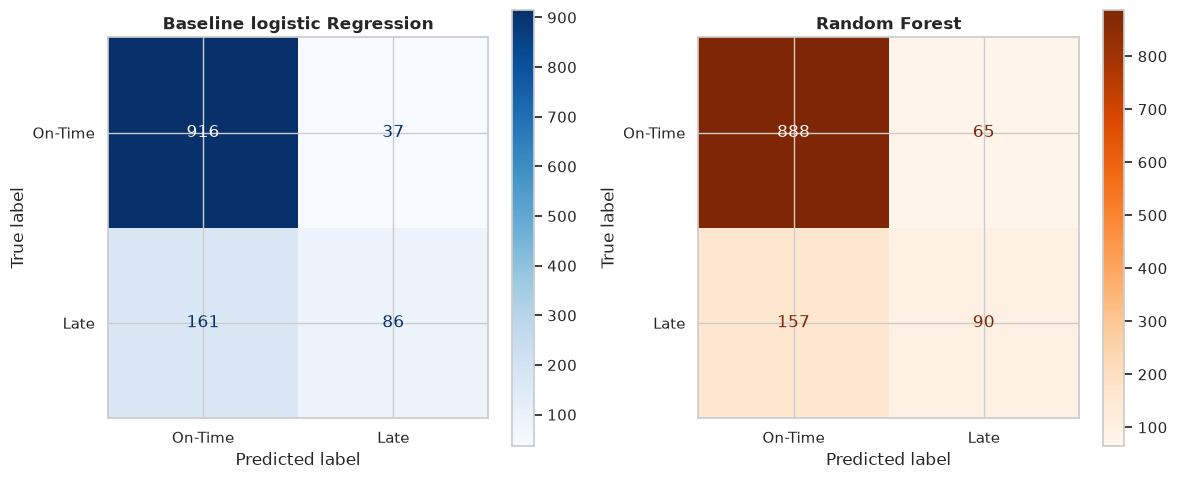

In [500]:
### next plot confusion matrices for both models to analyze false positives and false negatives
fig,axes=plt.subplots(1,2,figsize=(12,5))

ConfusionMatrixDisplay.from_predictions(
    y_test,y_pred_baseline,ax=axes[0],cmap='Blues',display_labels=['On-Time','Late']
    )
axes[0].set_title('Baseline logistic Regression', fontsize=12, weight='bold')

ConfusionMatrixDisplay.from_predictions(
    y_test,y_pred_rf,ax=axes[1],cmap='Oranges',display_labels=['On-Time','Late']
    )
axes[1].set_title('Random Forest',fontsize=12,weight='bold')

plt.tight_layout()
plt.show()

### a friendly remainder: the target (positive label) is 'delivered_late' (value 1) 

### Insights
- As we can see in the previous table, Random forest detects more real 'Late' values, less omited 'Late' (false negatives) but generates more false alarms ( false 'Late' values) which make work the logistics team a little more, preferable though
- I have trained and evaluated my classification models. The <u>Random Forest</u> classifier with class weight balancing achieved strong recall and f1-score on detecting **delivered_late** shipments. By reducing false negatives, this model allows the company dispatchers to intercept or prevent high risk shipments before delays occur
- <u>Random forest</u> is the winner model, even thou the presicion metric is slightly lower than in Logistic regression


# Block 8 - Model interpretability and automated Slack integration

### Block strategy
now I will analyze feature importances from the trained Random forest model to identify the key operational drivers behind shipment delays ==> idea from Gemini <==. Additionally, I will build an automated alert module that converts high-risk predictions into formatted JSON payloads to send real-time warnings to Slack dispatch channels as we did in past Class activity

==> Top 10 Most important features:


,Feature,Importance
9,traffic_index,0.073978
5,scheduled_transit_hours,0.070259
1,distance_km,0.069400
6,pickup_delay_minutes,0.060673
10,route_congestion_score,0.058275
7,driver_experience_years,0.056352
13,scheduled_speed_kmh,0.052563
2,weight_kg,0.048473
8,vehicle_age_years,0.047903
12,fuel_cost_cad,0.046378


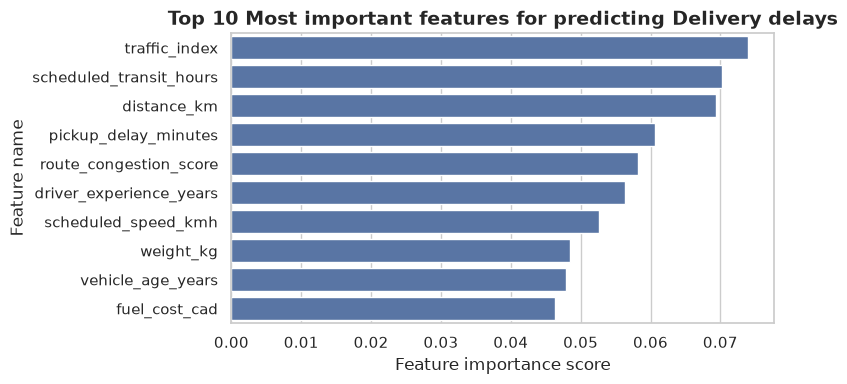

In [501]:
### extracting feature importances from the trained random forest classifier
importances=rf_model.feature_importances_
feature_imp_df = pd.DataFrame({
    # recovering the feature names
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

### displaying the top 10 most influential features
print("==> Top 10 Most important features:")
display(feature_imp_df.head(10))

### it is easy to notice when plotting horizontal bar chart of top 10 features for model interpretability
plt.figure(figsize=(8,4))
sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_imp_df.head(10)
)
plt.title('Top 10 Most important features for predicting Delivery delays',fontsize=14,weight='bold')
plt.xlabel('Feature importance score',fontsize=12)
plt.ylabel('Feature name',fontsize=12)
plt.tight_layout()
plt.show()

### Insights
the feature importance chart highlights the primary operational bottlenecks causing delivery delays:
- **distance_km** and **scheduled_transit_hours**: long transportation routes naturally carry higher cumulative disruption risks
- **pickup_delay_minutes** and **has_pickup_delay**: delays at origin heavily compound over transit time
- **scheduled_speed_kmh**: tight schedules requiring higher average speeds correlate strongly with late arrivals

In [502]:
### the Slack url is saved in the .env file
### I'm using the same Slack code structure from our previous class activity with that platform 
load_dotenv()

WEBHOOK_URL=os.getenv('SLACK_URL')

### I will define a function to construct and dispatch real-time slack alert payloads for high risk shipments ==> JSON structure from Google <==

def send_slack_message(shipment_id,origin,destination,carrier,weather_condition,risk_probability,webhook_url=WEBHOOK_URL):
   
    # define risk status label based on probability threshold
    if risk_probability>=0.75:
        risk_level='CRITICAL'
    else:
        risk_level='HIGH'
    
    # construct slack json block payload
    payload = {
        'blocks': [
            {
                'type': 'header',
                'text': {
                    'type': 'plain_text',
                    'text': f'Delay Warning: Shipment {shipment_id}'
                }
            },
            {
                'type': 'section',
                'text': {
                    'type':'mrkdwn',
                    'text':f'*MAPLEFREIGHT DISPATCH ALERT: ==> {risk_level} DELAY RISK DETECTED <==*'
                }
            },
            {
                'type': 'section',
                'fields': [
                    {'type': 'mrkdwn', 'text': f'*Origin:* {origin}'},
                    {'type': 'mrkdwn', 'text': f'*Destination:* {destination}'},
                    {'type': 'mrkdwn', 'text': f'*Carrier:* {carrier}'},
                    {'type': 'mrkdwn', 'text': f'*Predicted Risk:* {risk_probability:.2%}'}
                ]
            },
            {
                'type': 'section',
                'text': {
                    'type': 'mrkdwn',
                    'text': f'*Recommended Action:* Dispatch team should contact *{carrier}* immediately to reroute transit!!'
                }
            }
        ]
    }
    # send post request
    requests.post(WEBHOOK_URL, json=payload)

### preparing values for the drill
shipment_id='SHP_1111'
origin_city='Quebec'
destination_city='Ottawa'
carrier_name='HAUL'
weather_condition='Snow'
risk_probability = 0.90

# trigger Slack alert payload generation
send_slack_message(shipment_id,origin_city,destination_city,carrier_name,weather_condition,risk_probability)
print('==>Slack alert has been sent!!')

==>Slack alert has been sent!!
